In [12]:
import os
# https://stackoverflow.com/questions/20554074/sklearn-omp-error-15-initializing-libiomp5md-dll-but-found-mk2iomp5md-dll-a
os.environ["KMP_DUPLICATE_LIB_OK"]="TRUE"

import tqdm
import torch

print(torch.cuda.is_available())

import matplotlib.pyplot as plt


import importlib
import sys
from pathlib import Path
if os.name == 'nt':
    sys.path.append(os.getcwd() + "\\..\\src")    
    sys.path.append(os.getcwd() + "\\..\\src\\old")    
else:
    sys.path.append(os.getcwd() + "/../src")
    sys.path.append(os.getcwd() + "/../src/old")
print(sys.path)

import normflows as nf

import numpy as np
import tinycudann as tcnn

from multires_hash_encoding import MultiresEncoding, MultiresEncodingConfig

True
['p:\\Programs\\miniconda3\\envs\\master-pytorch\\python313.zip', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\DLLs', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib', 'p:\\Programs\\miniconda3\\envs\\master-pytorch', '', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib\\site-packages', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib\\site-packages\\win32', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib\\site-packages\\win32\\lib', 'p:\\Programs\\miniconda3\\envs\\master-pytorch\\Lib\\site-packages\\Pythonwin', 'd:\\Studium\\Masters\\Masters\\scripts\\..\\src', 'd:\\Studium\\Masters\\Masters\\scripts\\..\\src\\old', 'd:\\Studium\\Masters\\Masters\\scripts\\..\\src', 'd:\\Studium\\Masters\\Masters\\scripts\\..\\src\\old']


In [13]:
import norm_flow
import priors
import targets
import models
import input_encodings
import normalizing_flows
import torch_utils

importlib.reload(norm_flow)
importlib.reload(priors)
importlib.reload(targets)
importlib.reload(models)
importlib.reload(input_encodings)
importlib.reload(normalizing_flows)
importlib.reload(torch_utils)

from norm_flow import *
import priors
import targets
import models
from input_encodings import (build_hashgrid_encoding_conf, 
                             build_identity_encoding_conf, 
                             build_one_blob_encoding_conf,
                             build_spherical_harmonics_encoding)
import normalizing_flows
import torch_utils

Loading targets without having set a mitsuba variant: RendererTarget won't be available
Call mi.set_variant() to set one or see https://mitsuba.readthedocs.io/en/stable/


In [14]:
def get_encodings(input_dim, normal_context_size, pos_context_size, encode_normal_each_flow = False, encode_pos_each_flow = True):
    direction_encoding, _ = build_one_blob_encoding_conf(input_dim, 32)

    # normal_encoding, normal_enc_out = build_one_blob_encoding_conf(normal_context_size, 32) 

    # normal_encoding, normal_enc_out = (build_hashgrid_encoding_conf(normal_context_size, 16, 2) 
    #                                     if normal_context_size == 2 or normal_context_size == 3
    #                                     else build_one_blob_encoding_conf(normal_context_size, 16))
    
    normal_encoding, normal_enc_out = (build_spherical_harmonics_encoding(normal_context_size, 3) 
                                        if normal_context_size == 2 or normal_context_size == 3
                                        else build_one_blob_encoding_conf(normal_context_size, 16))

    positional_encoding, pos_enc_out = (build_hashgrid_encoding_conf(pos_context_size, 16, 2) 
                                        if pos_context_size == 2 or pos_context_size == 3
                                        else build_one_blob_encoding_conf(pos_context_size, 16))


    flow_normal_input = normal_context_size if encode_normal_each_flow else normal_enc_out
    flow_pos_input = pos_context_size if encode_pos_each_flow else pos_enc_out

    identity_normal_encoding, _ = build_identity_encoding_conf(flow_normal_input)
    identity_position_encoding, _ = build_identity_encoding_conf(flow_pos_input)

    model_enc_list = []
    if normal_context_size > 0: model_enc_list.append(normal_encoding if not encode_normal_each_flow  else identity_normal_encoding)
    if pos_context_size > 0: model_enc_list.append(positional_encoding if not encode_pos_each_flow     else identity_position_encoding)

    model_enc = None
    model_encoding_config = None
    if len(model_enc_list) > 0:
        model_encoding_config = {
            "otype": "Composite",
            "nested": model_enc_list
        }
        model_encoding_input_size = normal_context_size + pos_context_size

        model_enc = tcnn.Encoding(model_encoding_input_size, model_encoding_config)


    flow_enc_list = [direction_encoding]
    if normal_context_size > 0: flow_enc_list.append(normal_encoding     if encode_normal_each_flow  else identity_normal_encoding)
    if pos_context_size > 0: flow_enc_list.append(positional_encoding if encode_pos_each_flow     else identity_position_encoding)


    flow_encoding_config = {
        "otype": "Composite",
        "nested": flow_enc_list
    }

    model_context_out = model_enc.n_output_dims if model_enc else 0
    flow_enc = tcnn.Encoding(model_context_out + 1, flow_encoding_config)

    return model_encoding_config, flow_encoding_config, flow_normal_input + flow_pos_input


In [15]:
def get_default_prior(means, stds):
    return priors.DiagGaussianPrior(means, stds)

def get_default_target(domain, normalize = False):
    img = plt.imread('../assets/test_distributions/museum.jpg').sum(axis=-1)
    # img = plt.imread('../assets/test_distributions/Uniform_Env.png').sum(axis=-1)
    # img = plt.imread('../assets/test_distributions/Checkerboard.png')
    # img = plt.imread('../assets/test_distributions/TestDist2.png').sum(axis=-1)
    return targets.ImageTarget(img, domain = domain, normalize=normalize)

def build_Normflow_model(prior, 
                         domain,
                         num_flows = 4,
                         num_bins = 8,
                         hidden_units = 32, 
                         hidden_layers = 2,
                         normal_context_size = 0,
                         pos_context_size = 0,
                         encode_normal_each_flow = True,
                         encode_pos_each_flow = True) -> models.AbstractModel:
    

    input_dim           = 1

    model_enc_config, flow_enc_config, flow_context_size = get_encodings(input_dim, 
                                                                         normal_context_size, 
                                                                         pos_context_size, 
                                                                         encode_normal_each_flow=encode_normal_each_flow,
                                                                         encode_pos_each_flow=encode_pos_each_flow)

    net_config = {
        "otype": "FullyFusedMLP",    # Component type.
        "activation": "ReLU",        # Activation of hidden layers.
        "output_activation": "None", # Activation of the output layer.
        "n_neurons": hidden_units,            # Neurons in each hidden layer.
                                    # May only be 16, 32, 64, or 128.
        "n_hidden_layers": hidden_layers,        # Number of hidden layers.
    }
    
    flows = []

    for i in range(num_flows):
        flows += [normalizing_flows.NeuralSplineFlow(num_bins, flow_context_size, flow_enc_config, net_config)]


    return models.NormalizingFlowModel(prior, 
                                       flows, 
                                       normal_context_size + pos_context_size,
                                       model_enc_config,
                                       domain=domain)

def buildReparamModel(features, 
                    prior, 
                    encoding,
                    domain,
                    hidden_layers = 2, 
                    hidden_units = 16):
    hidden_layers = [hidden_units] * (hidden_layers + 1)

    return models.ReparameterizationModel(features, prior, encoding, hidden_layers, domain=domain)

def buildNaiveModel(features, 
                    prior, 
                    encoding,
                    domain,
                    hidden_layers = 2, 
                    hidden_units = 16):
    hidden_layers = [hidden_units] * (hidden_layers + 1)

    return models.NaiveForwardModel(features, prior, encoding, hidden_layers, domain=domain)

def sample_normals(num_samples, device):
    domain = torch.tensor([[2 * torch.pi, torch.pi]], device = device)
    phi_theta = torch.rand((num_samples, 2), device = device) * domain
    return torch_utils.to_vec3(phi_theta[..., 0], phi_theta[..., 1])
    

using device: cuda


C:\Users\janlu\AppData\Local\Temp\ipykernel_12368\3408605669.py:46: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


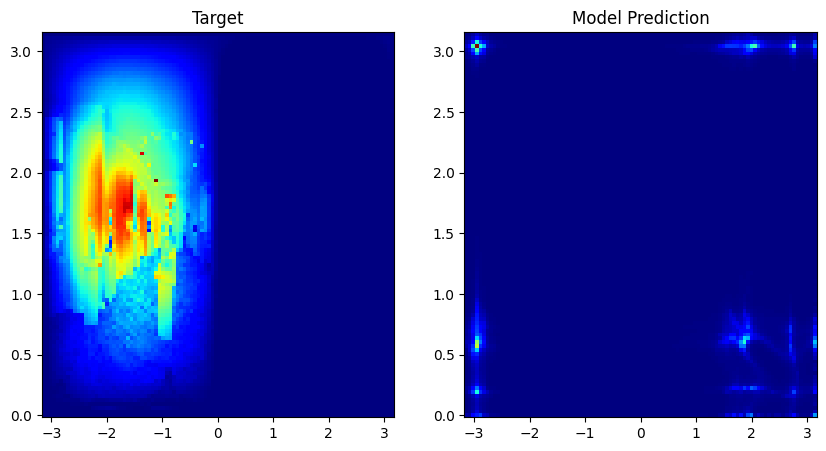

In [16]:
enable_cuda = True
device = torch.device('cuda' if torch.cuda.is_available() and enable_cuda else 'cpu')

# domain = torch.as_tensor([[0, torch.pi * 2], [0, torch.pi]], device = device)
domain = torch.as_tensor([[-torch.pi, torch.pi], [0, torch.pi]], device=device)
# domain = torch.as_tensor([[-1, 1], [-1, 1]], device = device)
means = (domain[:, 1] + domain[:, 0]) / 2
stds = (domain[:, 1] - domain[:, 0]) / (torch.pi)

# prior = get_default_prior(means, stds) 
# prior = priors.UniformPrior(domain)
prior = priors.CosineWeighted()
# encoding = get_default_encoding(2, device, False).to(device)
# encoding = encodings.OneBlobEncoding(2, 32).to(device)

normal_context_size = 3

model: models.AbstractModel = build_Normflow_model(prior, 
                                                   domain, 
                                                   num_flows = 8, 
                                                   num_bins = 8, 
                                                   hidden_units=128, 
                                                   hidden_layers=4,
                                                   normal_context_size=normal_context_size,
                                                   encode_normal_each_flow=True)

do_normals = normal_context_size > 0

# model = buildNaiveModel(2, prior, encoding, domain, hidden_layers=2, hidden_units=16)
# model = buildReparamModel(2, prior=prior, encoding=encoding, domain=domain, hidden_layers=4, hidden_units=64)

target = get_default_target(domain = domain, normalize=False)
# target = targets.UniformTarget(domain)


model.to(device)
target.to(device)
print(f"using device: {device}")

normal = None
if do_normals:
    normal = sample_normals(1, device = device).squeeze(0)


fig = model.visualize(target, normal = normal)
fig.show()

  0%|          | 0/1000 [00:00<?, ?it/s]

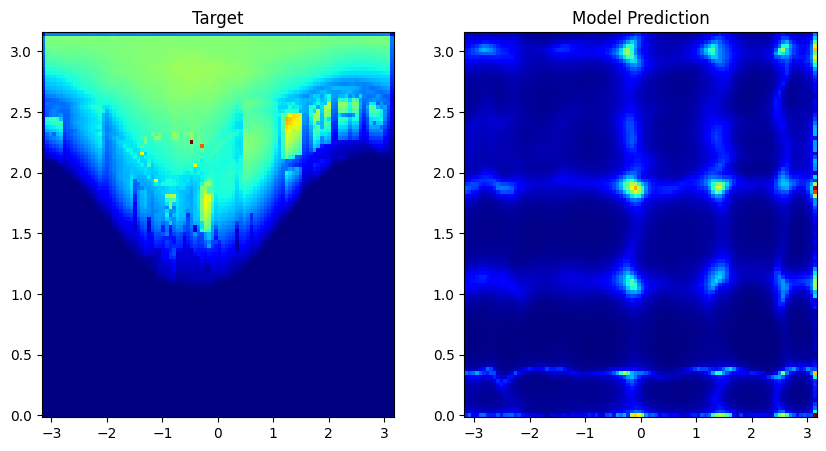

 10%|█         | 100/1000 [00:11<01:39,  9.01it/s]

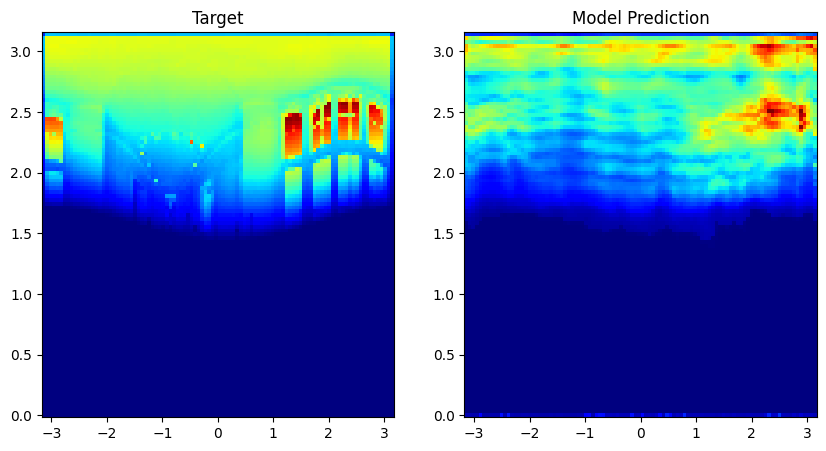

 20%|██        | 200/1000 [00:21<01:25,  9.35it/s]

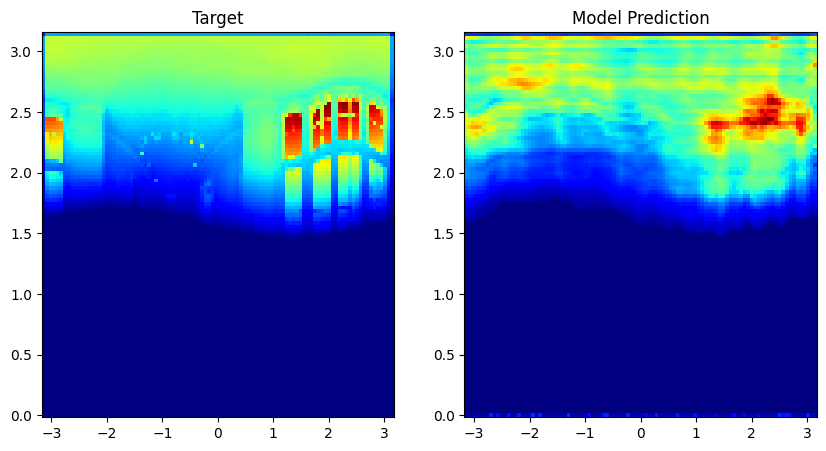

 30%|███       | 300/1000 [00:32<01:12,  9.62it/s]

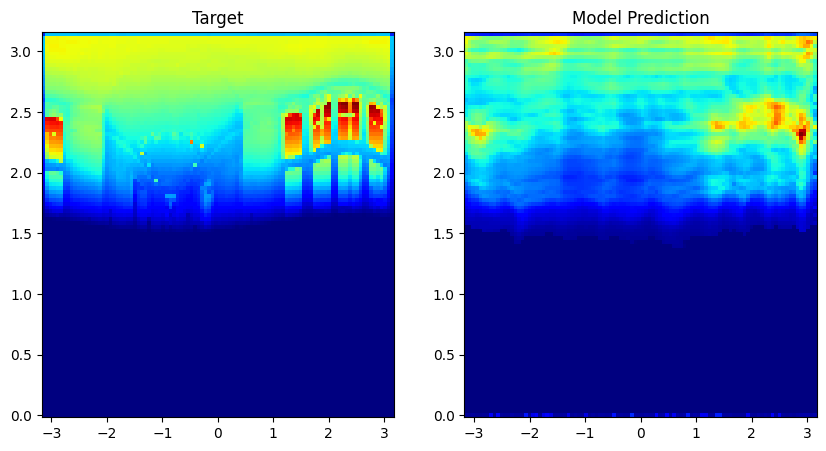

 40%|████      | 400/1000 [00:43<01:04,  9.36it/s]

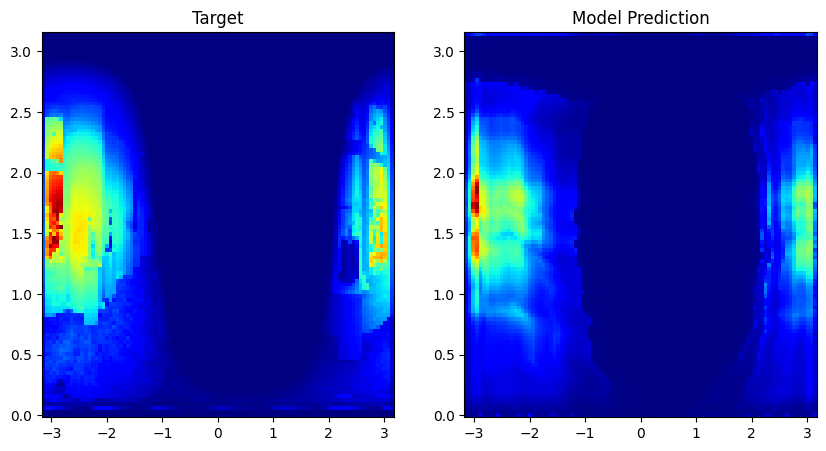

 50%|█████     | 500/1000 [00:54<00:53,  9.35it/s]

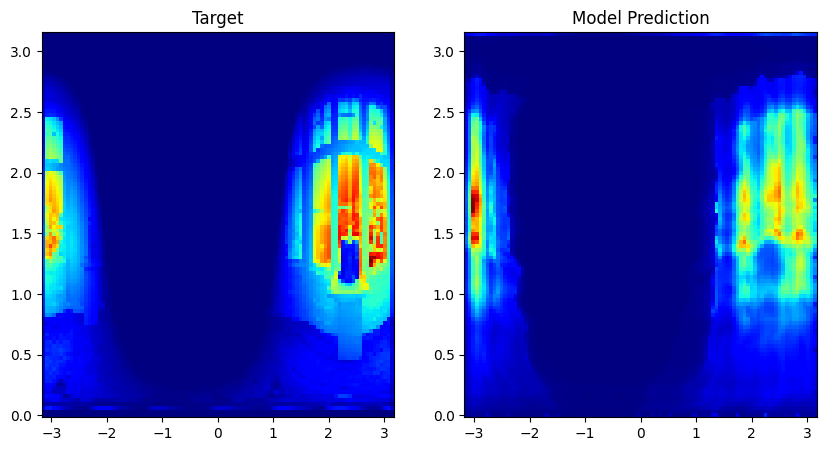

 60%|██████    | 600/1000 [01:05<00:42,  9.33it/s]

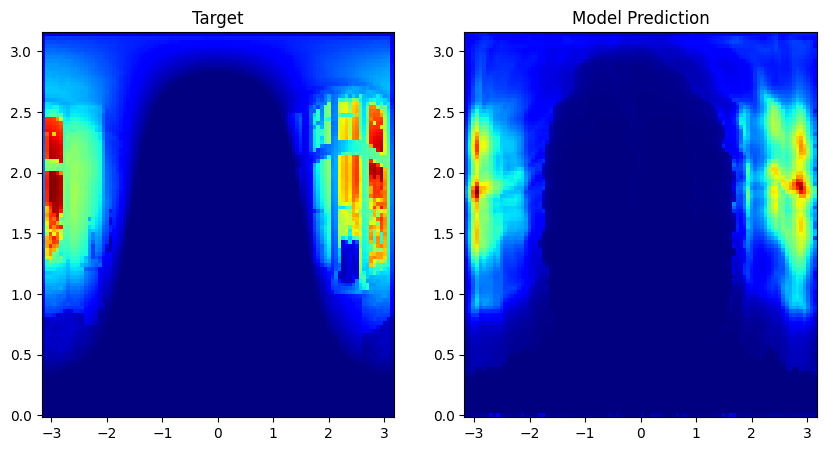

 70%|███████   | 700/1000 [01:15<00:32,  9.36it/s]

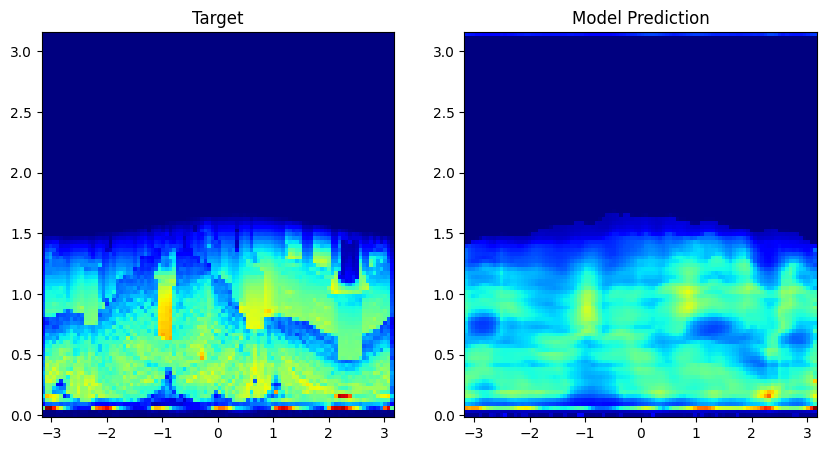

 80%|███████▉  | 799/1000 [01:25<00:13, 15.22it/s]

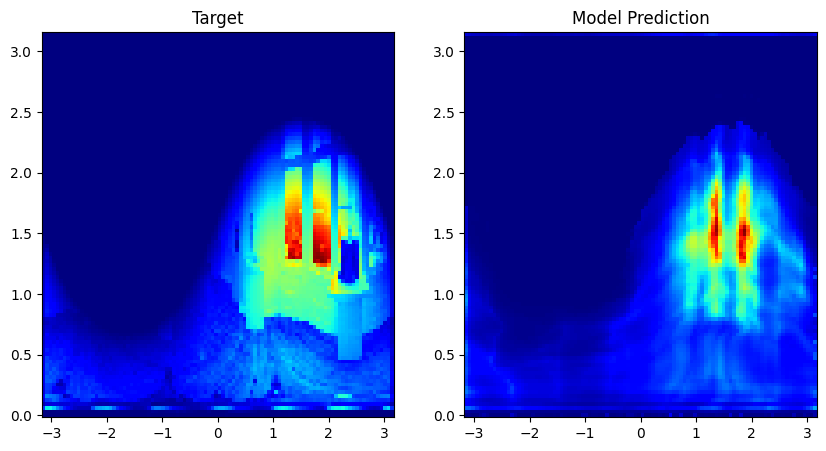

 90%|████████▉ | 899/1000 [01:32<00:06, 15.76it/s]

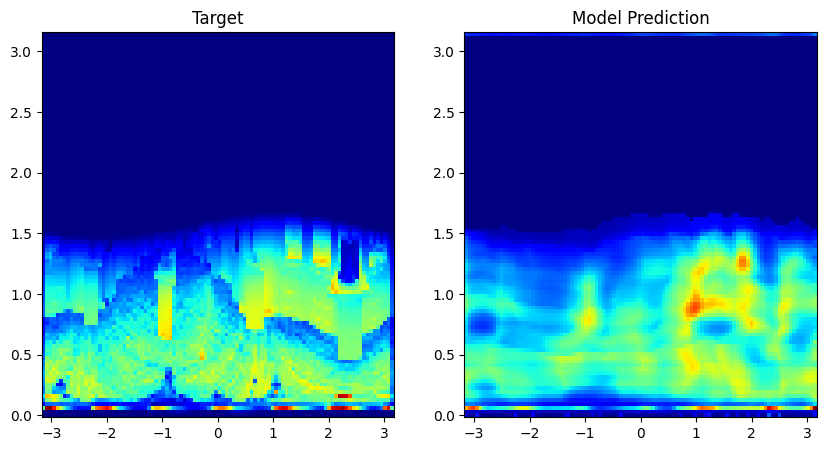

100%|██████████| 1000/1000 [01:38<00:00, 10.13it/s]


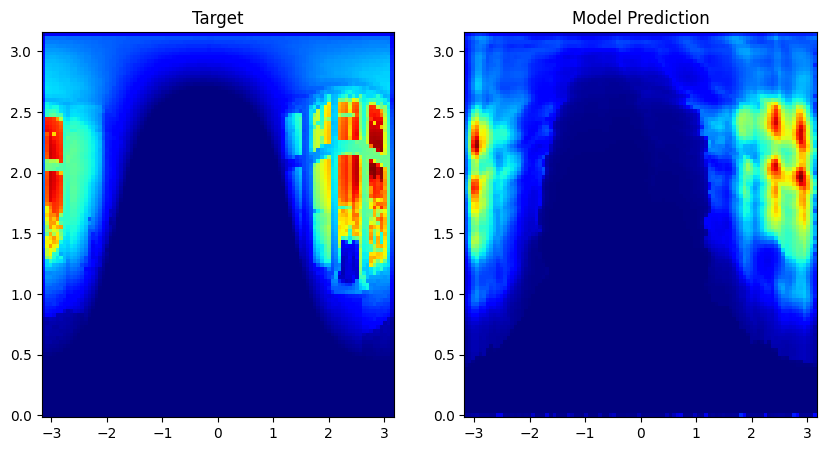

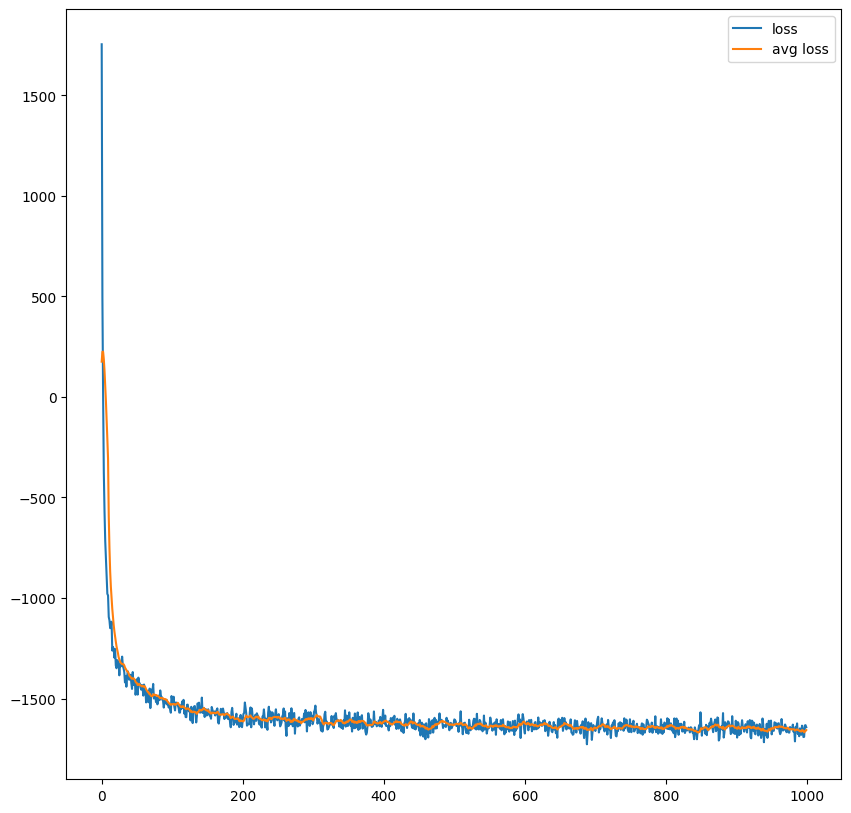

In [18]:
# Train model

iterations = 1000
num_samples = 2 ** 14

num_training_plots = 10
plot_every = int(iterations / num_training_plots if num_training_plots > 0 else iterations + 1)


moving_average_window = 10
loss_hist = np.array([])
avg_losses = np.array([])
dists_to_avg = np.array([])

clip_grad = True
clip_max_norm = 10


optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

iterator = tqdm.tqdm(range(iterations))
for it in iterator:
    optimizer.zero_grad()

    normals = None
    if do_normals:
        normals = sample_normals(num_samples, device = device)

    batch = torch.rand((num_samples, 2), device = device) * (domain[:, 1] - domain[:, 0]) + domain[:, 0]
    batch_pdf = 1 / torch.prod(domain[:, 1] - domain[:, 0])
    # batch, batch_pdf = model.sample(num_samples)
    # batch_pdf = batch_pdf.exp()

    # batch = model.prior.sample(num_samples, normals).to(device)
    # probs_q = model.prior.log_prob(batch, normals).exp().to(device)
    # batch_pdf = probs_q

    # log_probs_q = model.prior.log_prob(batch)
    # probs_q = torch.exp(log_probs_q)

    loss = model.compute_batch_gradient(target, 
                                        batch, 
                                        batch_pdf, 
                                        normals=normals)

    for p in model.parameters():
        if p.grad is not None:
            p.grad = torch.nan_to_num(p.grad)

    loss_hist = np.append(loss_hist, loss.to('cpu').data.numpy())
    avg_loss = np.sum(loss_hist[-moving_average_window:]) / moving_average_window

    loss_dist = np.abs(loss.to('cpu').data.numpy() - avg_loss)

    dists_to_avg = np.append(dists_to_avg, loss_dist)
    avg_losses = np.append(avg_losses, avg_loss)

    if clip_grad:
        ### Network and Encoding clipping
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=clip_max_norm)

    optimizer.step()
        
    
    if (it != 0 or plot_every < iterations) and it % plot_every == 0:
        normal = None
        if do_normals:
            normal = sample_normals(1, device = device).squeeze(0)

        fig = model.visualize(target, normal=normal)
        plt.show()

normal = None
if do_normals:
    normal = sample_normals(1, device = device).squeeze(0)

fig = model.visualize(target, normal=normal)
plt.show()

plt.figure(figsize=(10, 10))
plt.plot(loss_hist, label='loss')
plt.plot(avg_losses, label='avg loss')
plt.legend()
plt.show()

# plt.figure(figsize=(10, 10))
# plt.hist(dists_to_avg, 100)
# plt.show()

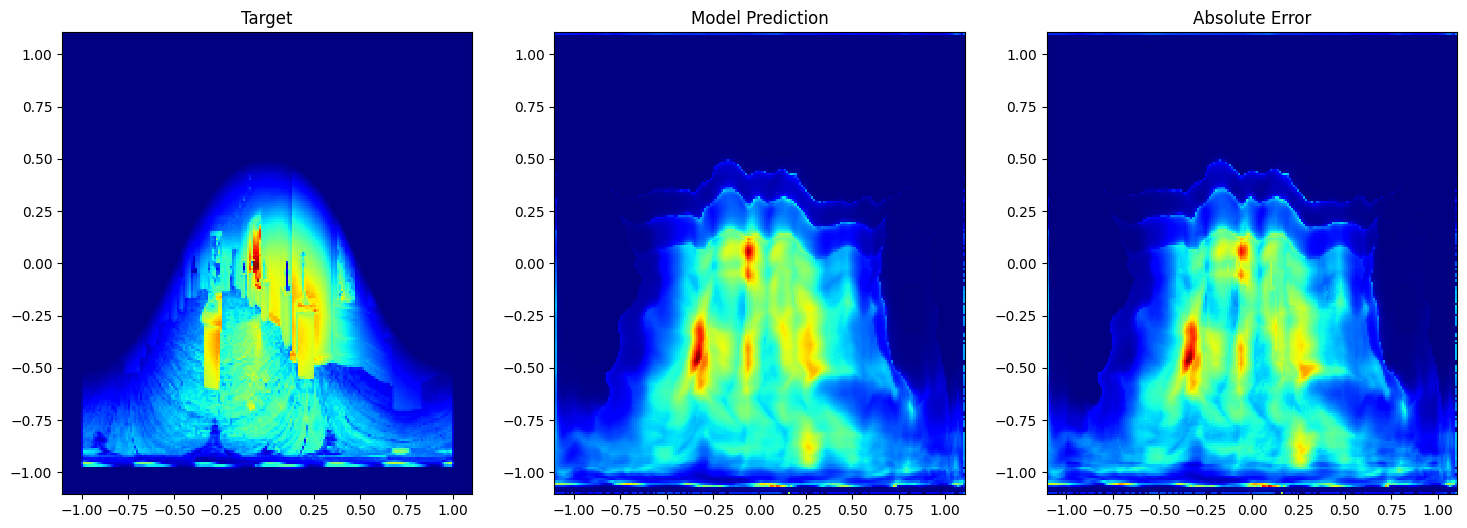

In [58]:
vis_domain = torch.as_tensor([[-1.1, 1.1], [-1.1, 1.1]], device = device)


if do_normals:
    # normal = torch.rand(3, device = device) * 2 - 1
    normal = torch.tensor([1, 0, 1], device = device, dtype=torch.float32)
    norm = normal.norm()
    normal = torch.where(norm > 0, normal / norm, normal)

fig = model.visualize(target, normal=normal, grid_size=200, domain=vis_domain)

C:\Users\janlu\AppData\Local\Temp\ipykernel_18992\2069730693.py:4: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


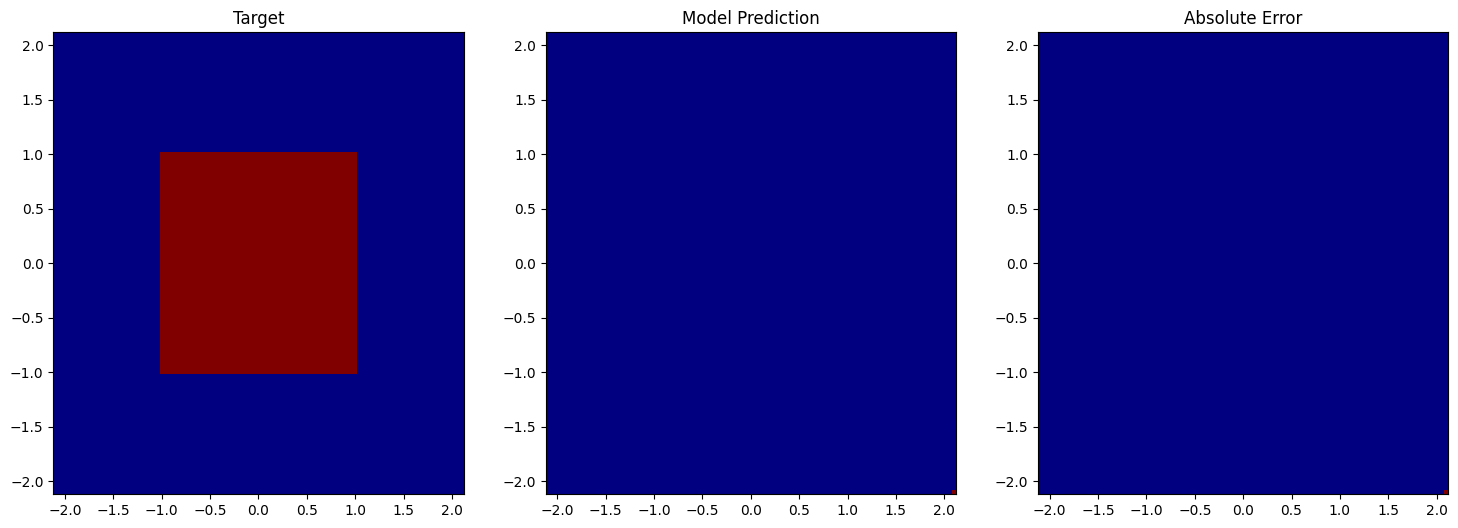

In [52]:
vis_domain = torch.as_tensor([[-2.1, 2.1], [-2.1, 2.1]], device = device)

fig = model.visualize(target, domain = vis_domain)
fig.show()

In [ ]:
num_samples = 500000

cos_prior = priors.CosineWeighted()

N = torch.tensor([[0, 1, 0]], device = device, dtype = torch.float32)


raw_samples = cos_prior.sample(num_samples, N)
# raw_samples = model.prior.sample(num_samples)

samples = model.forward(raw_samples)


out_samples = samples.detach().cpu()
# out_samples = raw_samples.detach().cpu()

plt.hist2d(out_samples[:, 0], out_samples[:, 1], bins = 50)
# plt.scatter(out_samples[:, 0], out_samples[:, 1])
plt.show()